## MODEL_EVALUATION

## 1 Accuracy and Loss

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay , classification_report
from pathlib import Path
from PIL import Image
from tensorflow.keras.models import load_model

In [2]:
PROJECT_DIR = Path("..")

TRAIN_DIR = PROJECT_DIR / "dataset" / "Training"
TEST_DIR = PROJECT_DIR / "dataset" / "Testing"
MODEL_DIR = PROJECT_DIR / "models"

In [3]:
ann_model = load_model(MODEL_DIR / "ann_brain_tumor.keras")
cnn_model = load_model(MODEL_DIR / "cnn_brain_tumor.keras")


In [4]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}
class_names = sorted(folder.name for folder in TRAIN_DIR.iterdir() if folder.is_dir())

class_to_label = {name: index for index, name in enumerate(class_names)}

test_paths = []
test_labels = []

for class_name in class_names:
    for path in (TEST_DIR / class_name).rglob("*"):
        if path.suffix.lower() in IMAGE_EXTENSIONS:
            test_paths.append(str(path))
            test_labels.append(class_to_label[class_name])

test_paths = np.array(test_paths)
test_labels = np.array(test_labels)

print("Test images:", len(test_paths))
print("Test labels:", len(test_labels))
print("Class mapping:", class_to_label)

Test images: 1600
Test labels: 1600
Class mapping: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [5]:
def preprocess_ann_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(image, channels=1)
    image.set_shape([None, None, 1])
    image = tf.image.resize(image, (224, 224))
    image = tf.cast(image, tf.float32) / 255.0
    image = tf.reshape(image, [50176])

    return image, label


BATCH_SIZE = 16 
ann_test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels)) 
ann_test_dataset = (ann_test_dataset.map(preprocess_ann_image, num_parallel_calls=tf.data.AUTOTUNE)
                                    .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

In [6]:
def preprocess_cnn_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(image,channels=1,expand_animations=False)
    image.set_shape([None, None, 1])
    image = tf.image.resize(image, (224, 224))
    image = tf.cast(image, tf.float32) / 255.0
    image = tf.ensure_shape(image, [224, 224, 1])

    return image, label

cnn_test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
cnn_test_dataset = (cnn_test_dataset.map(preprocess_cnn_image, num_parallel_calls=tf.data.AUTOTUNE)
                                    .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

In [7]:
ann_loss, ann_accuracy = ann_model.evaluate(ann_test_dataset)
cnn_loss, cnn_accuracy = cnn_model.evaluate(cnn_test_dataset)

print("ANN Test Accuracy:", ann_accuracy * 100)
print("ANN Test Loss:", ann_loss)

print("CNN Test Accuracy:", cnn_accuracy * 100)
print("CNN Test Loss:", cnn_loss) 

100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.7450 - loss: 1.4021
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 73ms/step - accuracy: 0.8313 - loss: 1.7823
ANN Test Accuracy: 74.50000047683716
ANN Test Loss: 1.4021005630493164
CNN Test Accuracy: 83.1250011920929
CNN Test Loss: 1.7823389768600464


In [8]:
results = {"Model": ["ANN", "CNN"],"Test Accuracy": [ann_accuracy, cnn_accuracy],"Test Loss": [ann_loss, cnn_loss]}

results_df = pd.DataFrame(results)
print(results_df)

  Model  Test Accuracy  Test Loss
0   ANN        0.74500   1.402101
1   CNN        0.83125   1.782339


## 2 Confusion Matrix

In [9]:
ann_predictions = np.argmax(ann_model.predict(ann_test_dataset),axis=1)

cnn_predictions = np.argmax(cnn_model.predict(cnn_test_dataset),axis=1)

print("ANN predictions:", ann_predictions.shape)
print("CNN predictions:", cnn_predictions.shape)

100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 71ms/step
ANN predictions: (1600,)
CNN predictions: (1600,)


In [10]:
ann_cm = confusion_matrix(test_labels, ann_predictions)
cnn_cm = confusion_matrix(test_labels, cnn_predictions)

print("ANN Confusion Matrix:\n", ann_cm)
print("\nCNN Confusion Matrix:\n", cnn_cm)

ANN Confusion Matrix:
 [[252  61  71  16]
 [ 72 224  80  24]
 [  0   4 396   0]
 [ 34  28  18 320]]

CNN Confusion Matrix:
 [[281  57  53   9]
 [ 33 324  39   4]
 [  2   0 397   1]
 [ 24  45   3 328]]


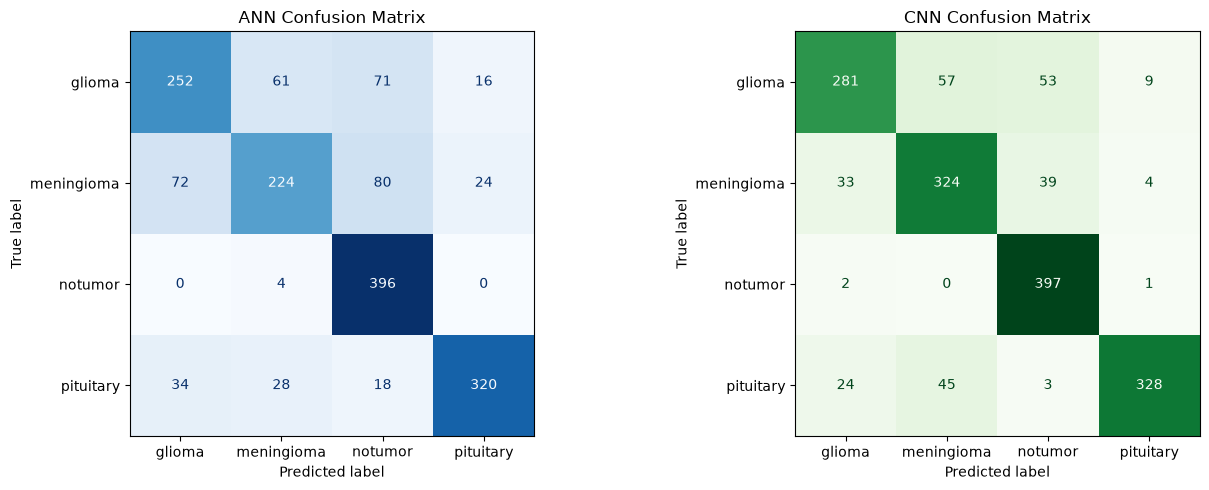

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay(confusion_matrix=ann_cm,display_labels=class_names).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("ANN Confusion Matrix")

ConfusionMatrixDisplay(confusion_matrix=cnn_cm,display_labels=class_names).plot(ax=axes[1], cmap="Greens", colorbar=False)
axes[1].set_title("CNN Confusion Matrix")

plt.tight_layout()
plt.show()

## 3 Precision, Recall and F1-score

In [12]:
ann_report = classification_report(test_labels,ann_predictions,target_names=class_names)

print("ANN Classification Report:\n")
print(ann_report)

ANN Classification Report:

              precision    recall  f1-score   support

      glioma       0.70      0.63      0.66       400
  meningioma       0.71      0.56      0.62       400
     notumor       0.70      0.99      0.82       400
   pituitary       0.89      0.80      0.84       400

    accuracy                           0.74      1600
   macro avg       0.75      0.74      0.74      1600
weighted avg       0.75      0.74      0.74      1600



In [13]:
cnn_report = classification_report(test_labels,cnn_predictions,target_names=class_names)

print("CNN Classification Report:\n")
print(cnn_report)

CNN Classification Report:

              precision    recall  f1-score   support

      glioma       0.83      0.70      0.76       400
  meningioma       0.76      0.81      0.78       400
     notumor       0.81      0.99      0.89       400
   pituitary       0.96      0.82      0.88       400

    accuracy                           0.83      1600
   macro avg       0.84      0.83      0.83      1600
weighted avg       0.84      0.83      0.83      1600



## 4  ANN vs CNN Comparison.

In [14]:
comparison = pd.DataFrame({"Metric": ["Test Accuracy", "Test Loss", "Macro Precision", "Macro Recall", "Macro F1-score"],
    "ANN": [ann_accuracy,ann_loss,0.75,0.74,0.74],
    "CNN": [cnn_accuracy,cnn_loss,0.84,0.83,0.83]})

print(comparison)

            Metric       ANN       CNN
0    Test Accuracy  0.745000  0.831250
1        Test Loss  1.402101  1.782339
2  Macro Precision  0.750000  0.840000
3     Macro Recall  0.740000  0.830000
4   Macro F1-score  0.740000  0.830000


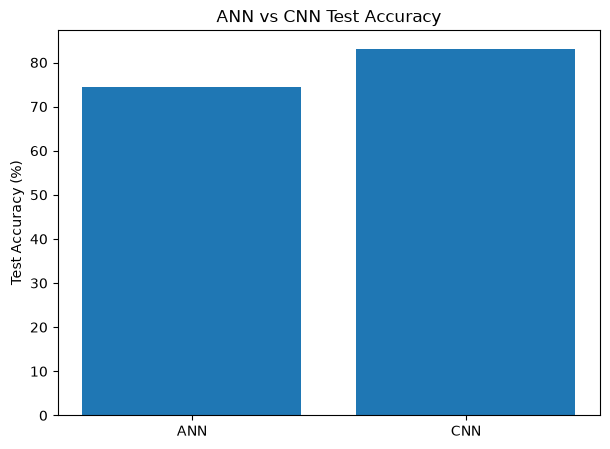

In [15]:
plt.figure(figsize=(7, 5))
plt.bar(["ANN", "CNN"],[ann_accuracy * 100, cnn_accuracy * 100])
plt.ylabel("Test Accuracy (%)")
plt.title("ANN vs CNN Test Accuracy")
plt.show()

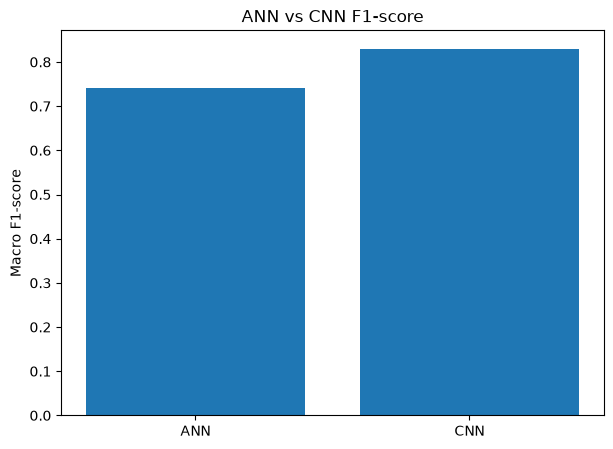

In [16]:
plt.figure(figsize=(7, 5))
plt.bar(["ANN", "CNN"],[0.74, 0.83])
plt.ylabel("Macro F1-score")
plt.title("ANN vs CNN F1-score")
plt.show()

## 5  Error Analysis

In [17]:
ann_errors = np.where(test_labels != ann_predictions)[0]
cnn_errors = np.where(test_labels != cnn_predictions)[0]

print("ANN incorrect predictions:", len(ann_errors))
print("CNN incorrect predictions:", len(cnn_errors))

ANN incorrect predictions: 408
CNN incorrect predictions: 270


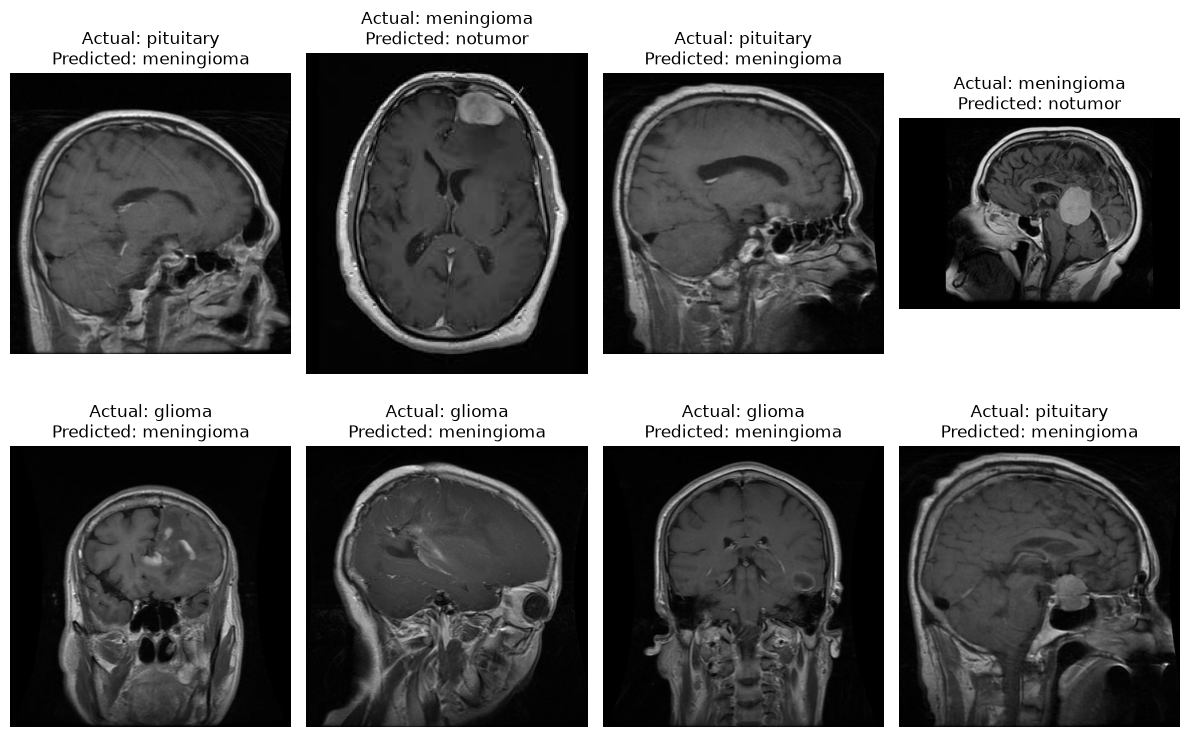

In [18]:
rng = np.random.default_rng(42)
sample_errors = rng.choice(cnn_errors,size=min(8, len(cnn_errors)),replace=False)

plt.figure(figsize=(12, 8))
for i, idx in enumerate(sample_errors):
    image = Image.open(test_paths[idx])
    plt.subplot(2, 4, i + 1)
    plt.imshow(image, cmap="gray")
    actual = class_names[test_labels[idx]]
    predicted = class_names[cnn_predictions[idx]]
    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()